In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate project root
root = Path.cwd()

if root.name == "notebooks":
    root = root.parent

# Load asset returns
file_path = root / "data" / "processed" / "asset_returns.csv"

df_assets = pd.read_csv(file_path)

tickers = ["SPY", "QQQ", "IWM", "EFA", "EEM"]

weights = np.array([0.40, 0.25, 0.15, 0.10, 0.10])

window = 500

# First 500-day estimation window
first_window = df_assets[tickers].iloc[:window]

print("Shape:", first_window.shape)
display(first_window.head())

Shape: (500, 5)


,SPY,QQQ,IWM,EFA,EEM
0,0.002647,0.000000,-0.003439,0.000881,0.007258
1,0.000704,-0.006032,-0.000941,0.004227,0.002092
2,0.004221,0.000650,0.007378,-0.003858,-0.005799
3,0.003328,0.008230,0.005454,0.007922,0.007932
4,0.001397,-0.004082,-0.004029,0.008210,-0.002083


In [2]:
# Estimate distribution parameters

mean_vector = first_window.mean().to_numpy()

cov_matrix = first_window.cov().to_numpy()

print("Mean Vector:")
print(mean_vector)

print("\nCovariance Matrix:")
print(cov_matrix)

Mean Vector:
[ 3.84669216e-04  5.13913018e-04  5.27623220e-04 -1.69180572e-05
  1.06666230e-05]

Covariance Matrix:
[[0.00016879 0.00016741 0.00022263 0.00020887 0.00021801]
 [0.00016741 0.00018575 0.00022537 0.00020329 0.00021445]
 [0.00022263 0.00022537 0.00032522 0.00026969 0.00028773]
 [0.00020887 0.00020329 0.00026969 0.00029647 0.00029067]
 [0.00021801 0.00021445 0.00028773 0.00029067 0.000338  ]]


In [3]:
# Step 3: Monte Carlo Simulation

n_simulations = 100_000

# Set random seed for reproducibility
rng = np.random.default_rng(42)

# Simulate correlated ETF daily returns
simulated_returns = rng.multivariate_normal(
    mean=mean_vector,
    cov=cov_matrix,
    size=n_simulations
)

print("Simulation Shape:", simulated_returns.shape)

print("\nFirst 5 Simulated Scenarios:")
print(simulated_returns[:5])

Simulation Shape: (100000, 5)

First 5 Simulated Scenarios:
[[-0.00551751  0.00444995 -0.00231916 -0.00554885 -0.01153454]
 [ 0.01495044  0.01718014  0.02326509  0.02114127  0.02454105]
 [-0.01031748 -0.00925185 -0.02110367 -0.01325352 -0.01184076]
 [ 0.01048162  0.01296474  0.01277794  0.01094213  0.0203051 ]
 [ 0.00340025  0.00534238  0.00588247  0.00574585 -0.00367425]]


In [4]:
rng.multivariate_normal(
    mean=mean_vector,
    cov=cov_matrix,
    size=100_000
)

array([[ 0.0109728 ,  0.0155877 ,  0.0127134 ,  0.00369911,  0.00612577],
       [ 0.01810199,  0.01699905,  0.01496451,  0.02283322,  0.01861304],
       [ 0.01125043,  0.01846838,  0.02488107,  0.0098385 ,  0.01649164],
       ...,
       [-0.00489456, -0.0061144 , -0.01134763, -0.00539108, -0.00517338],
       [ 0.0093064 ,  0.01015158,  0.01559714,  0.02253542,  0.0233018 ],
       [-0.01622926, -0.0201556 , -0.02127886, -0.02664636, -0.0173468 ]],
      shape=(100000, 5))

In [5]:
# Step 4: Simulated Portfolio Returns

simulated_portfolio_returns = simulated_returns @ weights

print("Portfolio Simulation Shape:",
      simulated_portfolio_returns.shape)

print("Simulated Portfolio Mean:",
      f"{simulated_portfolio_returns.mean():.4%}")

print("Simulated Portfolio Volatility:",
      f"{simulated_portfolio_returns.std(ddof=1):.4%}")

Portfolio Simulation Shape: (100000,)
Simulated Portfolio Mean: 0.0421%
Simulated Portfolio Volatility: 1.4399%


In [6]:
# Step 5: Compare theoretical and simulated moments

theoretical_mean = weights @ mean_vector

theoretical_volatility = np.sqrt(
    weights @ cov_matrix @ weights
)

simulated_mean = simulated_portfolio_returns.mean()
simulated_volatility = simulated_portfolio_returns.std(ddof=1)

comparison = pd.DataFrame({
    "Theoretical": [
        theoretical_mean,
        theoretical_volatility
    ],
    "Monte Carlo": [
        simulated_mean,
        simulated_volatility
    ]
}, index=["Mean", "Volatility"])

display(comparison.style.format("{:.4%}"))

,Theoretical,Monte Carlo
Mean,0.0361%,0.0421%
Volatility,1.4386%,1.4399%


In [7]:
# Step 6: Monte Carlo VaR

mc_var_95 = -np.quantile(
    simulated_portfolio_returns, 0.05
)

mc_var_99 = -np.quantile(
    simulated_portfolio_returns, 0.01
)

print(f"95% Monte Carlo VaR: {mc_var_95:.4%}")
print(f"99% Monte Carlo VaR: {mc_var_99:.4%}")

95% Monte Carlo VaR: 2.3131%
99% Monte Carlo VaR: 3.2870%


In [8]:
# Step 7: Monte Carlo Expected Shortfall

sorted_mc_returns = np.sort(simulated_portfolio_returns)

mc_es_95 = -sorted_mc_returns[:5000].mean()
mc_es_99 = -sorted_mc_returns[:1000].mean()

print(f"95% Monte Carlo ES: {mc_es_95:.4%}")
print(f"99% Monte Carlo ES: {mc_es_99:.4%}")

95% Monte Carlo ES: 2.9183%
99% Monte Carlo ES: 3.7764%


In [9]:
# Step 8: Monte Carlo vs Parametric Normal

from scipy.stats import norm

# Analytical Parametric VaR
z_95 = norm.ppf(0.95)
z_99 = norm.ppf(0.99)

param_var_95 = -theoretical_mean + z_95 * theoretical_volatility
param_var_99 = -theoretical_mean + z_99 * theoretical_volatility

# Analytical Parametric ES
param_es_95 = (
    -theoretical_mean
    + theoretical_volatility * norm.pdf(z_95) / 0.05
)

param_es_99 = (
    -theoretical_mean
    + theoretical_volatility * norm.pdf(z_99) / 0.01
)

comparison = pd.DataFrame({
    "Parametric": [
        param_var_95,
        param_var_99,
        param_es_95,
        param_es_99
    ],
    "Monte Carlo": [
        mc_var_95,
        mc_var_99,
        mc_es_95,
        mc_es_99
    ]
}, index=[
    "95% VaR",
    "99% VaR",
    "95% ES",
    "99% ES"
])

comparison["Difference"] = (
    comparison["Monte Carlo"] - comparison["Parametric"]
)

display(comparison.style.format("{:.4%}"))

,Parametric,Monte Carlo,Difference
95% VaR,2.3302%,2.3131%,-0.0171%
99% VaR,3.3106%,3.2870%,-0.0236%
95% ES,2.9313%,2.9183%,-0.0130%
99% ES,3.7980%,3.7764%,-0.0216%


In [10]:
# Step 9: Monte Carlo Convergence Test

simulation_sizes = [1000, 10000, 50000, 100000]

results = []

for n in simulation_sizes:

    sample = simulated_portfolio_returns[:n]

    # Monte Carlo VaR
    var_95 = -np.quantile(sample, 0.05)
    var_99 = -np.quantile(sample, 0.01)

    # Monte Carlo ES
    sorted_sample = np.sort(sample)

    es_95 = -sorted_sample[:int(n * 0.05)].mean()
    es_99 = -sorted_sample[:int(n * 0.01)].mean()

    results.append({
        "Simulations": n,
        "VaR_95": var_95,
        "VaR_99": var_99,
        "ES_95": es_95,
        "ES_99": es_99
    })

convergence_df = pd.DataFrame(results)

display(
    convergence_df.style.format({
        "VaR_95": "{:.4%}",
        "VaR_99": "{:.4%}",
        "ES_95": "{:.4%}",
        "ES_99": "{:.4%}"
    })
)

,Simulations,VaR_95,VaR_99,ES_95,ES_99
0,1000,2.3348%,3.2321%,2.8040%,3.4245%
1,10000,2.3429%,3.2428%,2.9182%,3.6903%
2,50000,2.3234%,3.2827%,2.9195%,3.7442%
3,100000,2.3131%,3.2870%,2.9183%,3.7764%


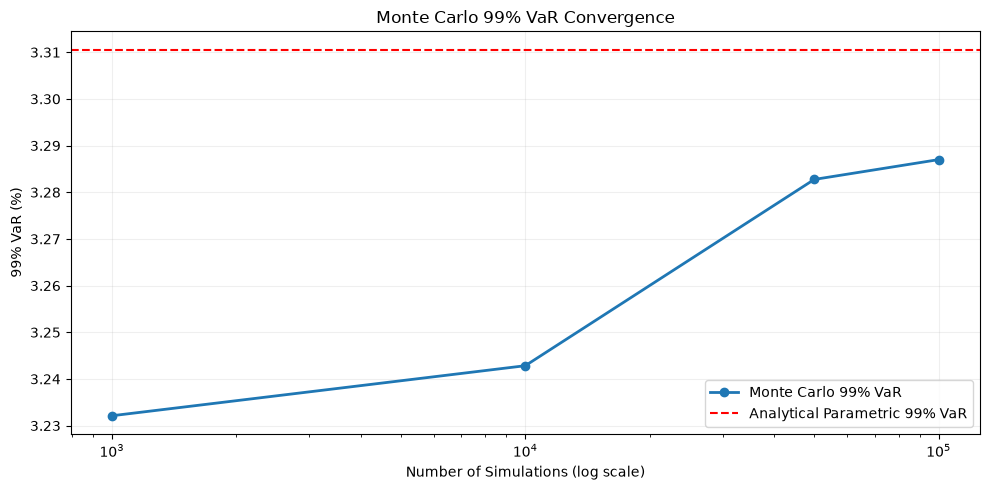

In [11]:
# Step 10: Visualize 99% VaR convergence

plt.figure(figsize=(10, 5))

plt.plot(
    convergence_df["Simulations"],
    convergence_df["VaR_99"] * 100,
    marker="o",
    linewidth=2,
    label="Monte Carlo 99% VaR"
)

plt.axhline(
    param_var_99 * 100,
    color="red",
    linestyle="--",
    label="Analytical Parametric 99% VaR"
)

plt.xscale("log")

plt.title("Monte Carlo 99% VaR Convergence")
plt.xlabel("Number of Simulations (log scale)")
plt.ylabel("99% VaR (%)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [12]:
import sys

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.monte_carlo_var import monte_carlo_var_es

mc_results = monte_carlo_var_es(
    mean_vector=mean_vector,
    cov_matrix=cov_matrix,
    weights=weights,
    n_simulations=100_000,
    seed=42
)

for key, value in mc_results.items():
    print(f"{key}: {value:.4%}")

var_95: 2.3131%
var_99: 3.2870%
es_95: 2.9183%
es_99: 3.7764%


In [13]:

# Step 15A: Rolling Monte Carlo Pilot

window = 500
n_simulations = 10_000
pilot_days = 20

forecast_results = []

for t in range(window, window + pilot_days):

    # Historical information available before forecast date
    historical_window = df_assets[tickers].iloc[t-window:t]

    # Estimate distribution parameters
    mu = historical_window.mean().to_numpy()
    cov = historical_window.cov().to_numpy()

    # Monte Carlo simulation
    mc = monte_carlo_var_es(
        mean_vector=mu,
        cov_matrix=cov,
        weights=weights,
        n_simulations=n_simulations,
        seed=42 + t - window
    )

    # Realized return is stored only for evaluation
    actual_return = float(
        df_assets[tickers].iloc[t].to_numpy() @ weights
    )

    forecast_results.append({
        "Date": df_assets["Date"].iloc[t],
        "actual_return": actual_return,
        "var_95": mc["var_95"],
        "var_99": mc["var_99"],
        "es_95": mc["es_95"],
        "es_99": mc["es_99"]
    })

mc_pilot_df = pd.DataFrame(forecast_results)

print("Pilot Forecasts:", len(mc_pilot_df))
display(mc_pilot_df.head())


Pilot Forecasts: 20


,Date,actual_return,var_95,var_99,es_95,es_99
0,2011-12-28,-0.014352,0.023429,0.032428,0.029182,0.036903
1,2011-12-29,0.010431,0.022990,0.032890,0.028959,0.038049
2,2011-12-30,-0.002924,0.023295,0.033277,0.029601,0.039067
3,2012-01-03,0.019430,0.023295,0.033432,0.029482,0.037830
4,2012-01-04,-0.000290,0.023069,0.033228,0.029183,0.037821


In [14]:
# Step 15B: Validate Monte Carlo Pilot

assert len(mc_pilot_df) == 20

assert mc_pilot_df["Date"].iloc[0] == "2011-12-28"

assert mc_pilot_df["Date"].is_unique

assert np.isfinite(
    mc_pilot_df[
        ["actual_return", "var_95", "var_99",
         "es_95", "es_99"]
    ].to_numpy()
).all()

assert (mc_pilot_df["var_99"] >= mc_pilot_df["var_95"]).all()
assert (mc_pilot_df["es_95"] >= mc_pilot_df["var_95"]).all()
assert (mc_pilot_df["es_99"] >= mc_pilot_df["var_99"]).all()

print("Monte Carlo Pilot Validation Passed!")

Monte Carlo Pilot Validation Passed!


In [15]:
parametric_path = (
    root / "results" / "parametric_var_es_forecasts.csv"
)

parametric_df = pd.read_csv(parametric_path)

comparison = mc_pilot_df.merge(
    parametric_df[
        ["Date", "actual_return", "var_99", "es_99"]
    ],
    on="Date",
    suffixes=("_mc", "_param"),
    validate="one_to_one"
)

assert len(comparison) == 20

assert np.allclose(
    comparison["actual_return_mc"],
    comparison["actual_return_param"],
    atol=1e-10,
    rtol=0
)

display(comparison.head())

print("Monte Carlo / Parametric Alignment Passed!")

,Date,actual_return_mc,var_95,var_99_mc,es_95,es_99_mc,actual_return_param,var_99_param,es_99_param
0,2011-12-28,-0.014352,0.023429,0.032428,0.029182,0.036903,-0.014352,0.033106,0.037980
1,2011-12-29,0.010431,0.022990,0.032890,0.028959,0.038049,0.010431,0.033172,0.038052
2,2011-12-30,-0.002924,0.023295,0.033277,0.029601,0.039067,-0.002924,0.033166,0.038048
3,2012-01-03,0.019430,0.023295,0.033432,0.029482,0.037830,0.019430,0.033177,0.038059
4,2012-01-04,-0.000290,0.023069,0.033228,0.029183,0.037821,-0.000290,0.033204,0.038094


Monte Carlo / Parametric Alignment Passed!


In [18]:
import sys

# Allow imports from the project root
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.historical_var import historical_var, historical_es

print("Historical VaR / ES functions imported successfully!")

Historical VaR / ES functions imported successfully!


In [19]:

# Step 16A: Full Rolling Monte Carlo Simulation

window = 500
n_simulations = 100_000

forecast_results = []

# Independent reproducible random streams per forecast
seed_sequence = np.random.SeedSequence(42)
child_seeds = seed_sequence.spawn(len(df_assets) - window)

for i, t in enumerate(range(window, len(df_assets))):

    # Use historical returns only
    historical_window = df_assets[tickers].iloc[t-window:t]

    # Estimate asset mean and covariance
    mu = historical_window.mean().to_numpy()
    cov = historical_window.cov().to_numpy()

    # Convert to portfolio mean and volatility
    mu_p = weights @ mu
    sigma_p = np.sqrt(weights @ cov @ weights)

    # Simulate portfolio returns directly
    rng = np.random.default_rng(child_seeds[i])

    simulated_portfolio = rng.normal(
        loc=mu_p,
        scale=sigma_p,
        size=n_simulations
    )

    # Estimate Monte Carlo VaR and ES
    var_95 = historical_var(simulated_portfolio, 0.95)
    var_99 = historical_var(simulated_portfolio, 0.99)

    es_95 = historical_es(simulated_portfolio, 0.95)
    es_99 = historical_es(simulated_portfolio, 0.99)

    # Store forecast
    forecast_results.append({
        "Date": df_assets["Date"].iloc[t],
        "actual_return": float(
            df_assets[tickers].iloc[t].to_numpy() @ weights
        ),
        "portfolio_mean": mu_p,
        "portfolio_volatility": sigma_p,
        "var_95": var_95,
        "var_99": var_99,
        "es_95": es_95,
        "es_99": es_99
    })

mc_rolling_df = pd.DataFrame(forecast_results)

print("Monte Carlo Forecasts:", len(mc_rolling_df))
display(mc_rolling_df.head())


Monte Carlo Forecasts: 3732


,Date,actual_return,portfolio_mean,portfolio_volatility,var_95,var_99,es_95,es_99
0,2011-12-28,-0.014352,0.000361,0.014386,0.023423,0.033317,0.029483,0.038116
1,2011-12-29,0.010431,0.000329,0.014401,0.023391,0.033062,0.029312,0.037792
2,2011-12-30,-0.002924,0.000352,0.014408,0.023362,0.033360,0.029441,0.038158
3,2012-01-03,0.019430,0.000342,0.014408,0.023372,0.033040,0.029273,0.037910
4,2012-01-04,-0.000290,0.000369,0.014432,0.023427,0.033202,0.029460,0.037968


In [20]:
print("Total Forecasts:", len(mc_rolling_df))
print("First Date:", mc_rolling_df["Date"].iloc[0])
print("Last Date:", mc_rolling_df["Date"].iloc[-1])

print("\nMissing Values:")
print(mc_rolling_df.isna().sum())

Total Forecasts: 3732
First Date: 2011-12-28
Last Date: 2026-10-30

Missing Values:
Date                    0
actual_return           0
portfolio_mean          0
portfolio_volatility    0
var_95                  0
var_99                  0
es_95                   0
es_99                   0
dtype: int64


In [21]:
# Step 17: Compare Monte Carlo and Parametric

parametric_path = (
    root / "results" / "parametric_var_es_forecasts.csv"
)

parametric_df = pd.read_csv(parametric_path)

comparison = mc_rolling_df.merge(
    parametric_df,
    on="Date",
    suffixes=("_mc", "_param"),
    validate="one_to_one"
)

# Check date alignment
assert len(comparison) == 3732

# Check actual returns
assert np.allclose(
    comparison["actual_return_mc"],
    comparison["actual_return_param"],
    atol=1e-10,
    rtol=0
)

# Compare 99% VaR estimation error
comparison["var_99_error"] = (
    comparison["var_99_mc"]
    - comparison["var_99_param"]
)

print("Mean Absolute Error (99% VaR):")
print(f"{comparison['var_99_error'].abs().mean():.4%}")

print("\nMaximum Absolute Error (99% VaR):")
print(f"{comparison['var_99_error'].abs().max():.4%}")

print("\nMonte Carlo / Parametric Alignment Passed!")

Mean Absolute Error (99% VaR):
0.0104%

Maximum Absolute Error (99% VaR):
0.0605%

Monte Carlo / Parametric Alignment Passed!


In [22]:
# Step 18: Export Monte Carlo Rolling Forecasts

output_dir = root / "results"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "monte_carlo_var_es_forecasts.csv"
)

mc_rolling_df.to_csv(output_path, index=False)

print("Saved to:", output_path)
print("Rows:", len(mc_rolling_df))

Saved to: /Users/tzuling/Desktop/HW/self project/portfolio-var-es-backtesting/results/monte_carlo_var_es_forecasts.csv
Rows: 3732


In [23]:
# Step 19: Validate all three model outputs

historical_df = pd.read_csv(
    root / "results" / "historical_var_es_forecasts.csv"
)

parametric_df = pd.read_csv(
    root / "results" / "parametric_var_es_forecasts.csv"
)

monte_carlo_df = pd.read_csv(
    root / "results" / "monte_carlo_var_es_forecasts.csv"
)

models = {
    "Historical": historical_df,
    "Parametric": parametric_df,
    "Monte Carlo": monte_carlo_df
}

reference = historical_df

for name, model_df in models.items():

    # Check observation counts
    assert len(model_df) == 3732

    # Check dates and their order
    assert model_df["Date"].equals(reference["Date"])

    # Check realized returns
    assert np.allclose(
        model_df["actual_return"],
        reference["actual_return"],
        atol=1e-10,
        rtol=0
    )

    # Check that forecasts contain only finite values
    assert np.isfinite(
        model_df[
            ["var_95", "var_99", "es_95", "es_99"]
        ].to_numpy()
    ).all()

    # Check basic mathematical ordering
    assert (model_df["var_99"] >= model_df["var_95"]).all()
    assert (model_df["es_95"] >= model_df["var_95"]).all()
    assert (model_df["es_99"] >= model_df["var_99"]).all()

    print(f"{name}: Validation Passed")

print("\nAll Three Models Aligned Successfully!")

Historical: Validation Passed
Parametric: Validation Passed
Monte Carlo: Validation Passed

All Three Models Aligned Successfully!
